# ML Network Intrusion Detector
**Author:** Vedant Mathur  
**Program:** IBM SkillsBuild Cybersecurity Bootcamp 2026 (BharatCares)  
**Dataset:** NSL-KDD (public benchmark for network intrusion detection)

## 1. What is this project?
Think of a **security guard at the gate of a network**. Thousands of connections arrive every minute.
Some are normal (someone browsing, sending email) and some are attacks (someone scanning ports, flooding the server).

In this project we **teach a machine learning model to play that guard**: given the details of one network
connection (duration, protocol, bytes sent, login failures, etc.), the model predicts **normal** or **attack**.

**Steps:** load data -> explore -> prepare -> train 3 models -> evaluate -> understand *why* the model decides.

## 2. Import libraries

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)   # graphs are saved here for the report
print("Libraries loaded")

Libraries loaded


## 3. Load the dataset
NSL-KDD comes as two files:
- **KDDTrain+** - used to *teach* the model
- **KDDTest+** - used to *test* the model on connections it has never seen (and it also contains attack types that are not in the training file, so it is a tough, realistic test)

Every row = one network connection with 41 features + a label (`normal` or an attack name).

> **Note:** NSL-KDD was published in 2009, so it does not represent modern (encrypted, cloud-based) traffic.
> It is still the standard learning benchmark for intrusion detection, which is why we use it here.

In [2]:
BASE = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/"
TRAIN_URL = BASE + "KDDTrain+.txt"
TEST_URL  = BASE + "KDDTest+.txt"

columns = [
    "duration","protocol_type","service","flag","src_bytes","dst_bytes","land",
    "wrong_fragment","urgent","hot","num_failed_logins","logged_in","num_compromised",
    "root_shell","su_attempted","num_root","num_file_creations","num_shells",
    "num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count",
    "srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate",
    "same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count",
    "dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
    "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate",
    "label","difficulty"
]

train_df = pd.read_csv(TRAIN_URL, names=columns)
test_df  = pd.read_csv(TEST_URL,  names=columns)

# 'difficulty' is just a helper column made by the dataset authors, not a network feature
train_df = train_df.drop(columns=["difficulty"])
test_df  = test_df.drop(columns=["difficulty"])

print("Training set:", train_df.shape)
print("Test set    :", test_df.shape)
train_df.head()

Training set: (125973, 42)
Test set    : (22544, 42)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal
1,0,udp,other,SF,146,0,0,0,0,0,...,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal
2,0,tcp,private,S0,0,0,0,0,0,0,...,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune
3,0,tcp,http,SF,232,8153,0,0,0,0,...,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal
4,0,tcp,http,SF,199,420,0,0,0,0,...,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal


## 4. Explore the data
First question: **how many normal vs attack connections do we have?**
The dataset has many attack names (neptune, smurf, satan...). We group them into the 4 standard families:

| Family | Plain meaning |
|---|---|
| **DoS** | Flooding a server so real users can't get in |
| **Probe** | Scanning the network to find weak spots (recon) |
| **R2L** | Remote attacker trying to get local access (e.g. password guessing) |
| **U2R** | Normal user trying to become admin/root |

In [3]:
attack_family = {}
for a in ["back","land","neptune","pod","smurf","teardrop","apache2","udpstorm","processtable","worm","mailbomb"]:
    attack_family[a] = "DoS"
for a in ["satan","ipsweep","nmap","portsweep","mscan","saint"]:
    attack_family[a] = "Probe"
for a in ["guess_passwd","ftp_write","imap","phf","multihop","warezmaster","warezclient",
          "spy","xlock","xsnoop","snmpguess","snmpgetattack","httptunnel","sendmail","named"]:
    attack_family[a] = "R2L"
for a in ["buffer_overflow","loadmodule","rootkit","perl","sqlattack","xterm","ps"]:
    attack_family[a] = "U2R"
attack_family["normal"] = "Normal"

for df in (train_df, test_df):
    df["family"] = df["label"].map(attack_family)
    # Binary target: 0 = normal, 1 = attack  (this is what our model will predict)
    df["target"] = (df["label"] != "normal").astype(int)

print("Missing values in train:", train_df.isnull().sum().sum())
print("Duplicate rows in train:", train_df.duplicated().sum())
print("Duplicate rows in test :", test_df.duplicated().sum())

# Safety check: every label must map to a family (no silent NaN)
assert train_df["family"].notna().all() and test_df["family"].notna().all()

# How many attack names appear ONLY in the test file (never seen during training)?
novel = sorted(set(test_df["label"]) - set(train_df["label"]))
print(f"Attack types only in the test file: {len(novel)} -> {novel}")
print()
print(train_df["family"].value_counts())

Missing values in train: 0


Duplicate rows in train: 0
Duplicate rows in test : 0
Attack types only in the test file: 17 -> ['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']

family
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64


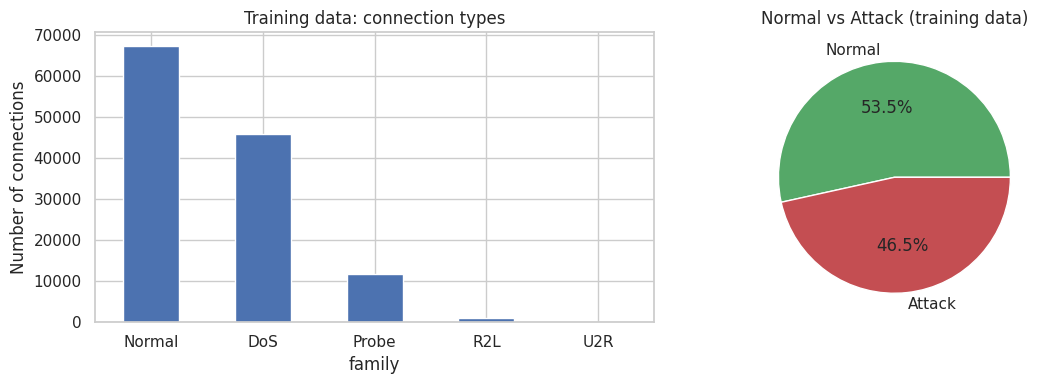

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

train_df["family"].value_counts().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Training data: connection types")
axes[0].set_ylabel("Number of connections")
axes[0].tick_params(axis="x", rotation=0)

train_df["target"].map({0: "Normal", 1: "Attack"}).value_counts().plot(
    kind="pie", ax=axes[1], autopct="%1.1f%%", colors=["#55A868", "#C44E52"])
axes[1].set_title("Normal vs Attack (training data)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig("figures/01_class_distribution.png", dpi=150)
plt.show()

**What we see:** the data is fairly balanced between normal and attack traffic, so a model can't win
just by always guessing one answer. DoS attacks are the biggest attack family; U2R is very rare (hard to detect).

## 5. Prepare the data
Models only understand numbers, so:
1. **Text columns** (`protocol_type`, `service`, `flag`) -> converted to 0/1 columns (*one-hot encoding*).
   Example: protocol `tcp` becomes `protocol_type_tcp = 1`, others `0`.
2. **Number columns** -> scaled to a similar range (*standardization*), so a big number like `src_bytes`
   doesn't overpower a small one like `duration`.

We build this as one `ColumnTransformer` that is **fitted only on training data** and then applied to the test data
(so the test data stays truly unseen - no cheating).

In [5]:
categorical_cols = ["protocol_type", "service", "flag"]
feature_cols = [c for c in columns if c not in ("label", "difficulty")]
numeric_cols = [c for c in feature_cols if c not in categorical_cols]

X_train, y_train = train_df[feature_cols], train_df["target"]
X_test,  y_test  = test_df[feature_cols],  test_df["target"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
])

X_train_p = preprocessor.fit_transform(X_train)
X_test_p  = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

print("Before preparing:", X_train.shape[1], "features")
print("After preparing :", X_train_p.shape[1], "features")

Before preparing: 41 features
After preparing : 122 features


## 6. Train three models
We try three different "guards" and compare them:

| Model | Plain-English idea |
|---|---|
| **Logistic Regression** | The simple baseline. Draws one straight dividing line between normal and attack. |
| **Random Forest** | A team of 100 decision trees that vote. Each tree asks yes/no questions like "were there many failed logins?" |
| **Isolation Forest** | *Anomaly detection.* Trained on **normal traffic only**. Anything that looks too different from normal gets flagged. Useful when you have no examples of attacks. |

In [6]:
# --- Model 1: Logistic Regression (baseline) ---
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_p, y_train)
pred_lr = log_reg.predict(X_test_p)

# --- Model 2: Random Forest (main model) ---
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(X_train_p, y_train)
pred_rf = rf.predict(X_test_p)

# --- Model 3: Isolation Forest (anomaly detection, learns from NORMAL traffic only) ---
X_train_normal = X_train_p[y_train.values == 0]
# contamination = the share of the (normal) training traffic we are willing to flag as 'unusual'.
# Here we choose 5% in advance, i.e. a ~5% false-alarm budget. It was NOT tuned on the test set.
iso = IsolationForest(n_estimators=200, contamination=0.05, random_state=RANDOM_STATE, n_jobs=-1)
iso.fit(X_train_normal)
pred_iso = (iso.predict(X_test_p) == -1).astype(int)   # -1 means anomaly -> attack (1)

print("All 3 models trained")

All 3 models trained


## 7. Evaluate the models
Accuracy alone can fool us, so we use 4 measures. In security, think of them like this:

- **Accuracy**: out of all connections, how many did we classify correctly?
- **Precision**: when the model shouts "attack!", how often is it really an attack? (low precision = lots of false alarms)
- **Recall**: out of all real attacks, how many did we catch? (**most important in security** - a missed attack is the costly mistake)
- **F1-score**: a single balanced score combining precision and recall.

In [7]:
def evaluate(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall":    recall_score(y_true, y_pred),
        "F1-score":  f1_score(y_true, y_pred),
    }

results = pd.DataFrame([
    evaluate("Logistic Regression", y_test, pred_lr),
    evaluate("Random Forest",       y_test, pred_rf),
    evaluate("Isolation Forest",    y_test, pred_iso),
]).set_index("Model").round(4)

results

,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.7537,0.9174,0.6234,0.7424
Random Forest,0.7648,0.9670,0.6075,0.7462
Isolation Forest,0.7884,0.9365,0.6740,0.7839


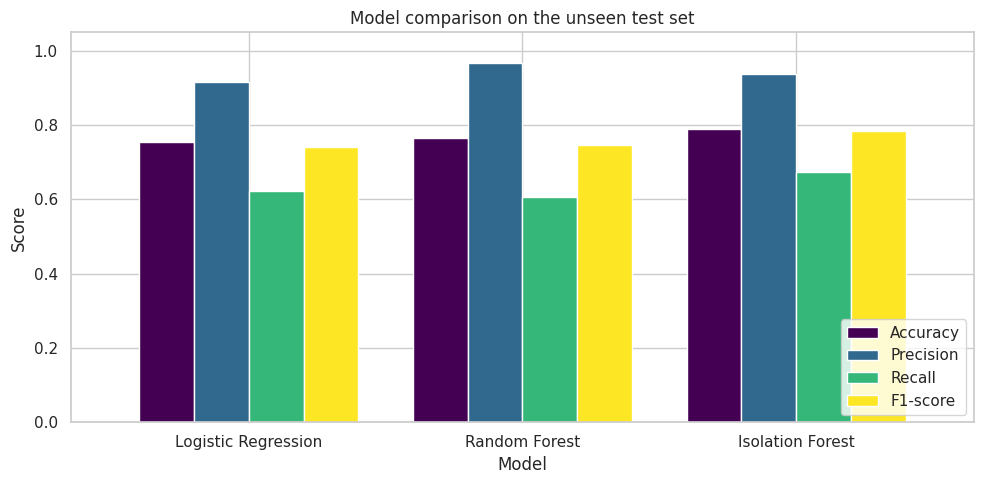

In [8]:
ax = results.plot(kind="bar", figsize=(10, 5), colormap="viridis", width=0.8)
ax.set_title("Model comparison on the unseen test set")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=0)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figures/02_model_comparison.png", dpi=150)
plt.show()

### A fair-comparison note about the Isolation Forest
The Isolation Forest is a different kind of model: it never sees a single attack during training, it only learns what
*normal* looks like. Its `contamination` setting decides how strict the guard is: a **stricter** guard catches more attacks
(higher recall) but raises more false alarms (lower precision). The table below shows this trade-off.
With the very strict 0.01 setting the Isolation Forest is actually slightly *worse* than the Random Forest on accuracy, and
from 0.05 upwards it is better. So 'Isolation Forest wins' depends on the setting; in a real deployment the setting would be
chosen from the false-alarm rate the security team can tolerate.

In [9]:
rows = []
for c in [0.01, 0.05, 0.10, 0.20]:
    m = IsolationForest(n_estimators=200, contamination=c, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train_normal)
    pr = (m.predict(X_test_p) == -1).astype(int)
    rows.append({"contamination": c,
                 "Accuracy": accuracy_score(y_test, pr),
                 "Precision": precision_score(y_test, pr),
                 "Recall": recall_score(y_test, pr)})
pd.DataFrame(rows).set_index("contamination").round(4)

,Accuracy,Precision,Recall
contamination,,,
0.01,0.7515,0.9824,0.5738
0.05,0.7884,0.9365,0.6740
0.10,0.7994,0.9272,0.7028
0.20,0.8434,0.8904,0.8265


### Reality check: why are the test scores lower than expected?
You may have noticed accuracy is only around 75-80%, which looks low for a Random Forest.
The reason: **the official test file contains attack types the model never saw in training**
(like a guard who has only studied some criminals' photos and then meets new ones).

To prove it, let's test the same Random Forest on a **random 20% slice of the training file**
(where attack types *do* overlap with what it learned).

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Split the RAW data first, then fit the preprocessing on the training part only (no leakage)
Xa_raw, Xb_raw, ya, yb = train_test_split(X_train, y_train, test_size=0.2,
                                          random_state=RANDOM_STATE, stratify=y_train)
check_model = Pipeline([
    ("prep", clone(preprocessor)),
    ("rf", RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE)),
]).fit(Xa_raw, ya)
pred_check = check_model.predict(Xb_raw)

print("Random Forest on a random split of the training file (familiar attacks):")
print(f"  Accuracy : {accuracy_score(yb, pred_check):.4f}")
print(f"  Recall   : {recall_score(yb, pred_check):.4f}")
print()
print("Random Forest on the official test file (includes NEW attack types):")
print(f"  Accuracy : {accuracy_score(y_test, pred_rf):.4f}")
print(f"  Recall   : {recall_score(y_test, pred_rf):.4f}")

Random Forest on a random split of the training file (familiar attacks):
  Accuracy : 0.9990
  Recall   : 0.9984

Random Forest on the official test file (includes NEW attack types):
  Accuracy : 0.7648
  Recall   : 0.6075


**Lesson:** the model is excellent at attacks it has seen before, but struggles with brand-new ones
(17 of the attack names in the test file never appear in training).
Part of the gap also comes from the test file having a somewhat different mix of traffic, and a random split of the
training file is an "easy" test because it contains many very similar records. So treat 99.9% as an upper bound, not a promise.
This is exactly the real-world problem in cybersecurity (new "zero-day" attacks keep appearing), and it is why
the anomaly-based Isolation Forest does comparatively well here: it does not need to have seen the attack before.

### Confusion matrices
A confusion matrix shows exactly **where** a model goes wrong:
- Top-left: normal traffic correctly allowed.
- Bottom-right: attacks correctly caught.
- Top-right: **false alarms** (normal flagged as attack).
- Bottom-left: **missed attacks** (the dangerous mistake).

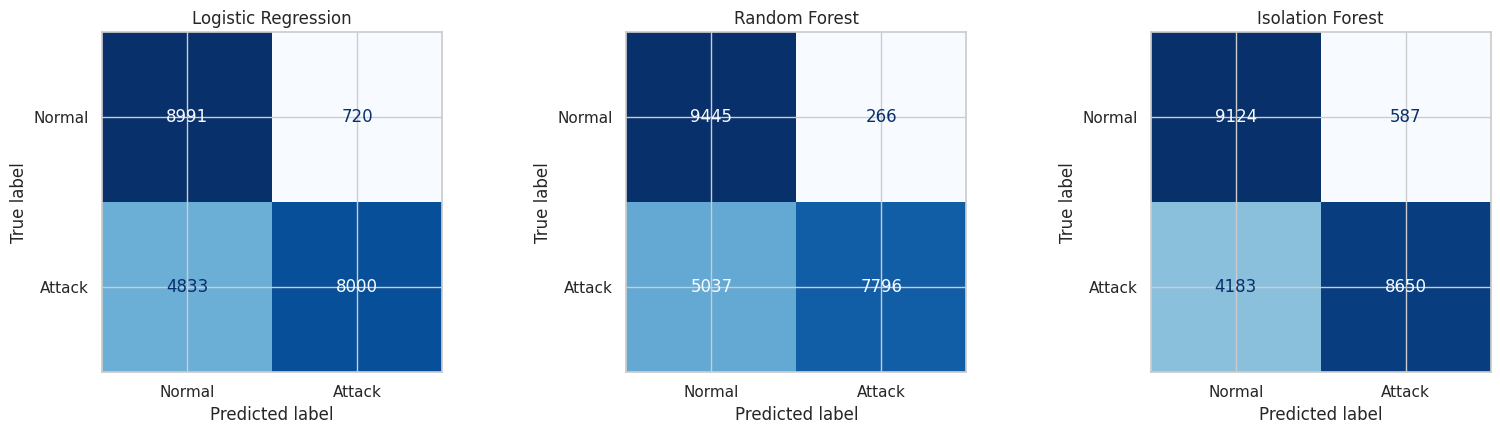

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, pred) in zip(axes, [("Logistic Regression", pred_lr),
                                   ("Random Forest", pred_rf),
                                   ("Isolation Forest", pred_iso)]):
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=["Normal", "Attack"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)
plt.tight_layout()
plt.savefig("figures/03_confusion_matrices.png", dpi=150)
plt.show()

In [12]:
print("Detailed report - Random Forest")
print(classification_report(y_test, pred_rf, target_names=["Normal", "Attack"]))

Detailed report - Random Forest
              precision    recall  f1-score   support

      Normal       0.65      0.97      0.78      9711
      Attack       0.97      0.61      0.75     12833

    accuracy                           0.76     22544
   macro avg       0.81      0.79      0.76     22544
weighted avg       0.83      0.76      0.76     22544



### Which attack types does the best model catch?
Overall numbers hide details, so let's check the **detection rate for each attack family**
(using the Random Forest).

,Attacks in test set,Detected (%)
family,,
DoS,7460,78.8
Probe,2421,72.7
U2R,67,11.9
R2L,2885,5.3


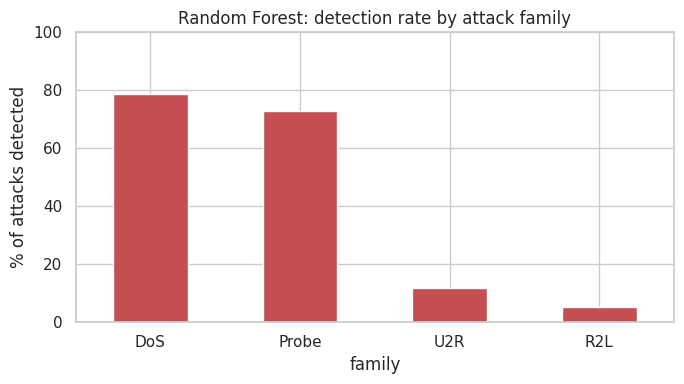

In [13]:
eval_df = test_df.copy()
eval_df["rf_pred"] = pred_rf

attacks_only = eval_df[eval_df["target"] == 1]
family_recall = (attacks_only.groupby("family")["rf_pred"].mean() * 100).round(1)
family_counts = attacks_only["family"].value_counts()

summary = pd.DataFrame({"Attacks in test set": family_counts,
                        "Detected (%)": family_recall}).sort_values("Detected (%)", ascending=False)
display(summary)

ax = summary["Detected (%)"].plot(kind="bar", color="#C44E52", figsize=(7, 4))
ax.set_title("Random Forest: detection rate by attack family")
ax.set_ylabel("% of attacks detected")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("figures/04_detection_by_family.png", dpi=150)
plt.show()

## 8. Why does the model decide this? (Feature importance)
A good security tool should be explainable. A Random Forest can tell us **which features mattered most**.
(Caveat: this built-in importance tends to favour features with many different values, such as `src_bytes`,
so treat the ranking as a helpful guide rather than exact proof.)

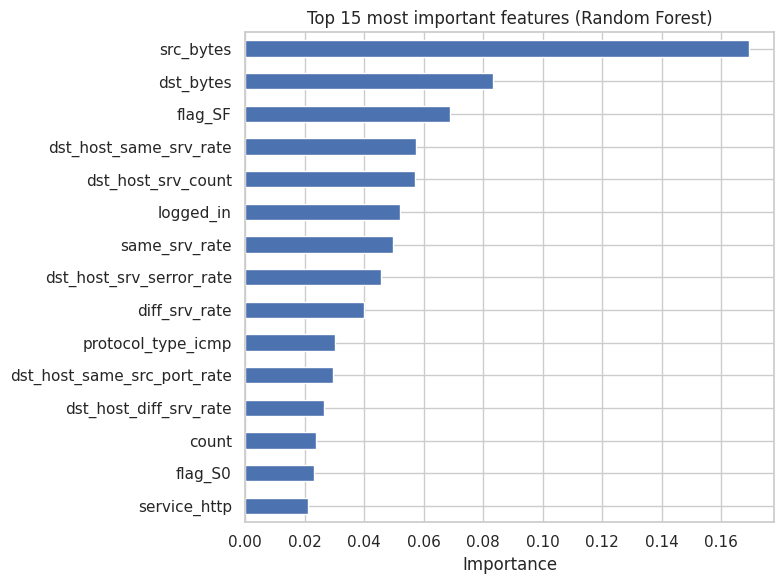

src_bytes                      0.1693
dst_bytes                      0.0832
flag_SF                        0.0687
dst_host_same_srv_rate         0.0573
dst_host_srv_count             0.0570
logged_in                      0.0520
same_srv_rate                  0.0497
dst_host_srv_serror_rate       0.0456
diff_srv_rate                  0.0400
protocol_type_icmp             0.0301
dst_host_same_src_port_rate    0.0296
dst_host_diff_srv_rate         0.0264
count                          0.0237
flag_S0                        0.0230
service_http                   0.0213
dtype: float64

In [14]:
importances = pd.Series(rf.feature_importances_, index=feature_names)
top15 = importances.sort_values(ascending=False).head(15)
top15.index = [n.split("__")[-1] for n in top15.index]   # clean the names

ax = top15.sort_values().plot(kind="barh", figsize=(8, 6), color="#4C72B0")
ax.set_title("Top 15 most important features (Random Forest)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.savefig("figures/05_feature_importance.png", dpi=150)
plt.show()

top15.round(4)

## 9. Try it: classify a single connection
This is how the detector would be used in real life - feed in one connection, get a verdict.

In [15]:
idx = list(y_test[y_test == 0].sample(3, random_state=7).index) +       list(y_test[y_test == 1].sample(3, random_state=7).index)
sample = X_test.loc[idx]
sample_pred = rf.predict(preprocessor.transform(sample))
sample_true = y_test.loc[idx]

demo = pd.DataFrame({
    "protocol": sample["protocol_type"],
    "service": sample["service"],
    "src_bytes": sample["src_bytes"],
    "Model says": np.where(sample_pred == 1, "ATTACK", "normal"),
    "Actually": np.where(sample_true == 1, "ATTACK", "normal"),
})
demo

,protocol,service,src_bytes,Model says,Actually
16288,tcp,http,340,normal,normal
21405,udp,domain_u,42,normal,normal
10930,tcp,http,286,normal,normal
22083,tcp,ftp,156,normal,ATTACK
758,tcp,http,54540,ATTACK,ATTACK
6692,tcp,http,54540,ATTACK,ATTACK


## 10. Conclusion
- We built an **ML-based Network Intrusion Detector** on the public NSL-KDD dataset and compared three models.
- On completely unseen traffic (KDDTest+), accuracy was about **75-79%** for all three models.
  The **Isolation Forest** scored best overall (accuracy 0.788, recall 0.674; note it is a different kind of model and its
  strictness setting trades recall against false alarms), while the **Random Forest** had the
  highest precision (0.967) - when it says "attack", it is almost always right - but it missed about 39% of attacks.
- The reality check showed why: on attacks it had already seen, the Random Forest is nearly perfect, but the test file
  contains **new attack types**, which is the classic "zero-day" problem.
- Detection by family: **DoS (~79%) and Probe (~73%)** are caught well; **R2L (~5%) and U2R (~12%)** are almost invisible
  to the model, because they are rare in the training data and look very similar to normal behaviour.
- Feature importance shows the model relies on sensible signals such as traffic volume (`src_bytes`, `dst_bytes`),
  connection status (`flag_SF`) and how many connections go to the same service, so its decisions are explainable.

**Limitations (being honest):**
- NSL-KDD is an older benchmark; modern traffic and attacks look different.
- Rare attack types (U2R, R2L) are the weak spot and would need special handling.
- Scores depend on the tough train/test mismatch described above; this is realistic but lowers the numbers.

**Future improvements:** use a newer dataset (CIC-IDS2017), add cross-validation, tune hyperparameters, use permutation importance, balance the rare attack classes
(e.g. SMOTE or class weights), combine the supervised and anomaly models, and wrap the best model in a small dashboard
for live traffic.